Trough FEV1 (vs Placebo):


,LS_Mean_Diff,CI_Lower,CI_Upper
Group,,,
Indacaterol600,0.1908,0.0670,0.3146
Indacaterol300,0.2043,0.0805,0.3281
Indacaterol75,0.2871,0.1633,0.4109
Indacaterol150,0.2183,0.0945,0.3421
Formoterol,0.1119,-0.0119,0.2357
Tiotropium,0.0602,-0.0636,0.1840



AUC1-4h (vs Placebo):


,LS_Mean_Diff,CI_Lower,CI_Upper
Group,,,
Indacaterol600,0.2719,0.1474,0.3965
Indacaterol300,0.3673,0.2428,0.4919
Indacaterol75,0.3575,0.2329,0.4820
Indacaterol150,0.3632,0.2386,0.4877
Formoterol,0.2481,0.1236,0.3727
Tiotropium,0.2344,0.1099,0.3590



Threshold X = 0.1200  (candidates: [np.float64(0.0602), np.float64(0.1119), 0.12])
Threshold Y = 0.2481  (candidates: [np.float64(0.2344), np.float64(0.2481)])

Rule triggered: 1
Reason: Multiple doses meet both; select lowest (Indacaterol75) + next higher
Selected: Indacaterol75 and Indacaterol150


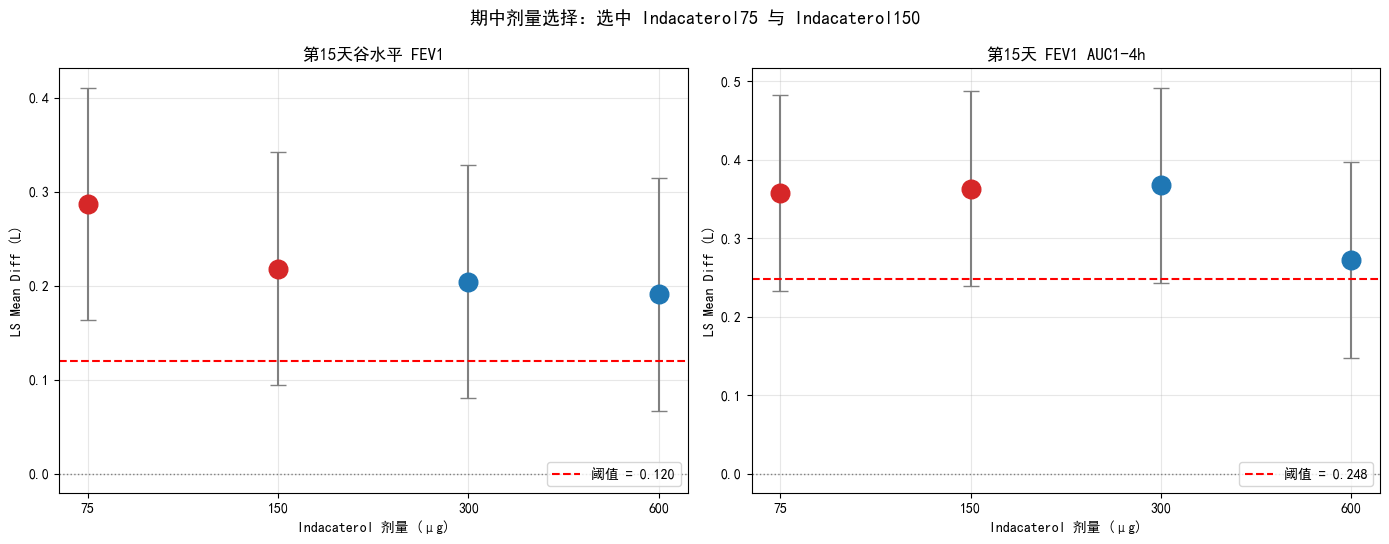

In [1]:
# ===== Notebook 03: Interim Analysis and Dose Selection =====
from src.randomization import stratified_block_randomization
from src.simulate import simulate_baseline, merge_with_randomization, simulate_endpoints
from src.analysis import get_lsmean_diff, compute_thresholds
from src.dose_selection import select_doses, plot_dose_selection
from src import config

# Rebuild data up to DATA3
random_df = stratified_block_randomization(seed=1128)
data1 = simulate_baseline(random_df, seed=1128)
data2 = merge_with_randomization(data1, random_df)
data3 = simulate_endpoints(data2, seed=1128)

# ANCOVA
res_trough = get_lsmean_diff(data3, 'FEV1_Trough_D15')
res_auc = get_lsmean_diff(data3, 'FEV1_AUC_1_4h_D15')

print("Trough FEV1 (vs Placebo):")
display(res_trough[['LS_Mean_Diff', 'CI_Lower', 'CI_Upper']].round(4))

print("\nAUC1-4h (vs Placebo):")
display(res_auc[['LS_Mean_Diff', 'CI_Lower', 'CI_Upper']].round(4))

# Thresholds
X, Y, X_cands, Y_cands = compute_thresholds(res_trough, res_auc)
print(f"\nThreshold X = {X:.4f}  (candidates: {[round(v,4) for v in X_cands]})")
print(f"Threshold Y = {Y:.4f}  (candidates: {[round(v,4) for v in Y_cands]})")

# Dose selection
chosen_low, chosen_high, rule, reason = select_doses(res_trough, res_auc, X, Y)
print(f"\nRule triggered: {rule}")
print(f"Reason: {reason}")
print(f"Selected: {chosen_low} and {chosen_high}")

# Plot
plot_dose_selection(
    res_trough.loc[list(config.DOSE_ORDER)],
    res_auc.loc[list(config.DOSE_ORDER)],
    X, Y, chosen_low, chosen_high,
    'outputs/figures/dose_selection.png'
)